In [3]:
import os
import scanpy as sc
import seaborn as sns
from tqdm import tqdm
from pathlib import Path

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.amp import autocast, GradScaler

from Henosis.dataprocess.h5a import H5ADTokenizer
from Henosis.const import set_species_context
from Henosis import data
import Henosis.resa as resa
import Henosis.utils as utils
import Henosis.mmd as mmd
import Henosis.lr_schedule as lr_sche
import Henosis.henosis as henosis

In [4]:
organ='testis'
PROJECT_ROOT = Path.cwd()
DATA_ROOT = Path(
    os.environ.get("HENOSIS_DATA_DIR", PROJECT_ROOT / "data")
).expanduser()

DATA_DIR = f"{DATA_ROOT}/figure2/{organ}"

In [5]:
organ='testis'
species_to_adata = {
    "homo_sapiens": sc.read_h5ad(f"{DATA_DIR}/h5ad/{organ}/homo_sapiens.h5ad"),
    "Mus_musculus": sc.read_h5ad(f"{DATA_DIR}/h5ad/{organ}/Mus_musculus.h5ad"),
    "Macaca_mulatta": sc.read_h5ad(f"{DATA_DIR}/h5ad/{organ}/Macaca_mulatta.h5ad"),
    "Callithrix_jacchus": sc.read_h5ad(f"{DATA_DIR}/h5ad/{organ}/Callithrix_jacchus.h5ad"),
    "Gallus_gallus": sc.read_h5ad(f"{DATA_DIR}/h5ad/{organ}/Gallus_gallus.h5ad"),
    "Monodelphis_domestica": sc.read_h5ad(f"{DATA_DIR}/h5ad/{organ}/Monodelphis_domestica.h5ad"),
    "Pan_troglodytes": sc.read_h5ad(f"{DATA_DIR}/h5ad/{organ}/Pan_troglodytes.h5ad"),
    "Gorilla_gorilla":sc.read_h5ad(f"{DATA_DIR}/h5ad/{organ}/Gorilla_gorilla.h5ad"),
    "Ornithorhynchus_anatinus":sc.read_h5ad(f"/{DATA_DIR}/h5ad/{organ}/Ornithorhynchus_anatinus.h5ad"),
}


In [6]:
species_to_embed_file = {
    "homo_sapiens": f"{DATA_DIR}/embedding/{organ}/homo_sapiens.avg.embeddings",
    "Mus_musculus": f"{DATA_DIR}/embedding/{organ}/Mus_musculus.avg.embeddings",
    "Macaca_mulatta": f"{DATA_DIR}/embedding/{organ}/Macaca_mulatta.avg.embeddings",
    "Callithrix_jacchus": f"{DATA_DIR}/embedding/{organ}/Callithrix_jacchus.avg.embeddings",
    "Gallus_gallus": f"{DATA_DIR}/embedding/{organ}/Gallus_gallus.avg.embeddings",
    "Monodelphis_domestica": f"{DATA_DIR}/embedding/{organ}/Monodelphis_domestica.avg.embeddings",
    "Pan_troglodytes": f"{DATA_DIR}/embedding/{organ}/Pan_troglodytes.avg.embeddings",
    "Gorilla_gorilla": f"{DATA_DIR}/embedding/{organ}/Gorilla_gorilla.avg.embeddings",
    "Ornithorhynchus_anatinus": f"{DATA_DIR}/embedding/{organ}/Ornithorhynchus_anatinus.avg.embeddings",
}

In [7]:
set_species_context(species_to_adata)

{'homo_sapiens': 0,
 'Mus_musculus': 1,
 'Macaca_mulatta': 2,
 'Callithrix_jacchus': 3,
 'Gallus_gallus': 4,
 'Monodelphis_domestica': 5,
 'Pan_troglodytes': 6,
 'Gorilla_gorilla': 7,
 'Ornithorhynchus_anatinus': 8}

In [8]:
tokenized = H5ADTokenizer(
    species_to_adata,
    species_to_embed_file,
).process_species_adata()

100%|██████████| 6751/6751 [00:00<00:00, 38138.61it/s]


In [9]:
species_to_reps = {
    "homo_sapiens": "X_pca",
    "Mus_musculus": "X_pca_harmony",
    "Macaca_mulatta": "X_pca",
    "Callithrix_jacchus": "X_pca",
    "Gallus_gallus": "X_pca",
    "Monodelphis_domestica": "X_pca_harmony",
    "Pan_troglodytes": "X_pca",
    "Gorilla_gorilla": "X_pca_harmony",
    "Ornithorhynchus_anatinus": "X_pca",
}

In [10]:
train_loader, test_loader = data.prepare_multispecies_dataloaders(
    tokenized,
    batch_size=512,
    species_to_reps=species_to_reps,
    batch_species=9,
)

homo_sapiens: X_pca
Mus_musculus: X_pca_harmony
Macaca_mulatta: X_pca
Callithrix_jacchus: X_pca
Gallus_gallus: X_pca
Monodelphis_domestica: X_pca_harmony
Pan_troglodytes: X_pca
Gorilla_gorilla: X_pca_harmony
Ornithorhynchus_anatinus: X_pca


In [11]:
embed_size=480
d_model=120
scale=4
input_size=50
latent_size=64
num_layers=1
n_clusters=100000
#net=resa.ReSA(species_to_embed_file,d_model,embed_size,latent_size,num_layers,scale=scale,)
net=henosis.Henosis(species_to_embed_file,d_model,embed_size,latent_size,encoder_type='mean_pool')

PCA ing
PCA done


In [12]:
def train_epoch(net,train_loader,loss_fn,loss_fn1,optimizer,scaler,device,current_temp,scheduler,ml_weight=1.0):
    net.train()
    metrics=utils.Accumulator(4)
    pbar=tqdm(train_loader,desc='Processing')
    for _,batch in enumerate(pbar):
        optimizer.zero_grad(set_to_none=True)

        data,adata,sp=batch
        data = data.to(device, non_blocking=True)
        adata = adata.float().to(device, non_blocking=True)
        sp = sp.to(device, non_blocking=True)

        with autocast('cuda'):
            sl = torch.tensor(0.0, device=device)
            protein_features,gene_features,logit_scales=net(adata,data,sp,)
            species_ids = torch.unique(sp).tolist()
            #for i in torch.unique(sp):
            for s in species_ids:
                mask = (sp == s)

                indices = torch.nonzero(mask).squeeze(1)
                protein_features_i = torch.index_select(protein_features, 0, indices)
                gene_features_i = torch.index_select(gene_features, 0, indices)
                sl += loss_fn(protein_features_i, gene_features_i, logit_scales[int(s)],)
            ml=loss_fn1(protein_features,sp)
            loss=sl+ml*ml_weight

        scaler.scale(loss).backward()
        if net.transformer.embed.gene_embed.weight.grad is not None:
            #net.transformer.embed.gene_embed.weight.grad[3:-1] = 0
            net.transformer.embed.gene_embed.weight.grad[4:] = 0
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(net.parameters(), max_norm=1.0)
        scaler.step(optimizer)
        scaler.update()

        if scheduler:
            scheduler.step()
        lr=optimizer.param_groups[0]['lr']
        pbar.set_description(f"loss:{loss.detach().item():.4f},sl:{sl.detach().item():.8f},ml:{ml.detach().item():.8f},lr:{lr:.8f}")
        metrics.add(loss.detach().item() * len(sp), sl.detach().item() * len(sp),ml.detach().item() * len(sp), len(sp))

    return {'loss':metrics[0] / metrics[3],'sl':metrics[1] / metrics[3],'ml':metrics[2] / metrics[3],}

def train(net,train_loader,test_loader,epochs,lr,species_to_h5,net_path,temp,ml_weight):
    def init_weights(m):
        if type(m) == nn.Linear or type(m) == nn.Conv1d:
            nn.init.xavier_uniform_(m.weight)
    net.apply(init_weights)
    print('init done')

    device =torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    print('training on', device)
    net.to(device)

    loss_fn=resa.MultiScaleReSALoss()#swav.ATACKNNLoss()#
    loss_fn1=mmd.MMMD(kernel_type='rbf',each=True)#mmd.MSampleLoss(each=True)#
    optimizer = torch.optim.AdamW(net.parameters(), lr=lr,fused=True)
    scheduler = lr_sche.CosineAnnealingWarmupRestarts(
        optimizer,
        first_cycle_steps=2000,   # 一个周期 2000 batch
        cycle_mult=1,             # 不增加周期长度
        max_lr=lr*1.5,            # 最大 lr 稍高
        min_lr=1e-6,
        warmup_steps=400,         # 前 400 batch 线性升到 max_lr
        gamma=0.6
    )
    early_stopping = utils.EarlyStopping(
        patience=10,               # 连续5个epoch指标不提升就停止
        verbose=True, 
        path=net_path, # 保存的文件名
        mode='min'                # 如果监控的是准确率，这里改用 'max'
    )
    scaler = GradScaler('cuda')
    cr_ml_weight=0.0
    warm_epoch=5
    try:
        for epoch in range(epochs):
            print(f"epoch:{epoch},")
            print(f"Temp: {temp}")
            if epoch>=warm_epoch:
                cr_ml_weight=ml_weight
            losses=train_epoch(net,train_loader,loss_fn,loss_fn1,optimizer,scaler,device,temp,scheduler,cr_ml_weight)
            current_lr = optimizer.param_groups[0]['lr']
            print(f"lr:{current_lr},")
            print(f'{losses}')
            if epoch>=warm_epoch:
                early_stopping(losses['loss'],net)
                if early_stopping.early_stop:
                    print("====== Early stopping triggered! ======")
                    #infer_latent(net,test_loader,device,fcell_path,fsp_path,species_to_h5)
                    break
            if epoch ==epochs-1:
                torch.save(net.state_dict(), net_path)
                print(f'saving weight in {net_path}')
                #infer_latent(net,test_loader,device,fcell_path,fsp_path,species_to_h5)
                break
    except KeyboardInterrupt:
        #infer_latent(net,test_loader,device,fcell_path,fsp_path,species_to_h5)
        torch.save(net.state_dict(), net_path)
        print(f'saving weight in {net_path}')

In [10]:
net_path=f'/mnt/public5/panguanyu/cross_species/gefor/code/pth/ReSA_{organ}.pth'

In [13]:
net_path=f'/mnt/public5/panguanyu/cross_species/gefor/code/pth/ReSA_{organ}.pth'
species_to_h5=tokenized
epochs=100
lr=1e-3
train(net,train_loader,test_loader,epochs,lr,species_to_h5,net_path,temp=0.2,ml_weight=1.0)

init done
training on cuda
epoch:0,
Temp: 0.2


Processing:   0%|          | 0/234 [00:00<?, ?it/s]

loss:27.2788,sl:27.27880287,ml:0.23844714,lr:0.00087792: 100%|██████████| 234/234 [00:31<00:00,  7.51it/s]


lr:0.000877915,
{'loss': 30.544467738550953, 'sl': 30.544467738550953, 'ml': 0.7470274021864957}
epoch:1,
Temp: 0.2


loss:24.5918,sl:24.59176254,ml:0.17459850,lr:0.00149333: 100%|██████████| 234/234 [00:30<00:00,  7.76it/s]


...

lr:5.424442765726848e-06,
{'loss': 22.89330176002959, 'sl': 22.753961921757103, 'ml': 0.13933986673752466}
EarlyStopping counter: 8 out of 10
epoch:96,
Temp: 0.2


loss:22.8782,sl:22.73939705,ml:0.13877800,lr:0.00000507: 100%|██████████| 234/234 [00:29<00:00,  7.99it/s]


lr:5.0724848687874364e-06,
{'loss': 22.89406883207142, 'sl': 22.75521238441141, 'ml': 0.138856498667827}
EarlyStopping counter: 9 out of 10
epoch:97,
Temp: 0.2


loss:22.7691,sl:22.64216042,ml:0.12694414,lr:0.00000434: 100%|██████████| 234/234 [00:29<00:00,  7.85it/s]

lr:4.336498579088457e-06,
{'loss': 22.887804764967697, 'sl': 22.749004820473175, 'ml': 0.1388000029529262}
EarlyStopping counter: 10 out of 10
====== Early stopping triggered! ======


infering: 100%|██████████| 157/157 [00:03<00:00, 49.66it/s]

computing PCA
    with n_comps=25


    finished (0:00:00)
Running MOT_Correction by 'inferred_species' -> adata.obsm['X_mot']
X_mot shape: (80019, 25)
computing neighbors


/mnt/public5/panguanyu/environment/mconda3/miniconda3/envs/crs_env/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:43)
computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm)
    'umap', UMAP parameters (adata.uns) (0:00:57)


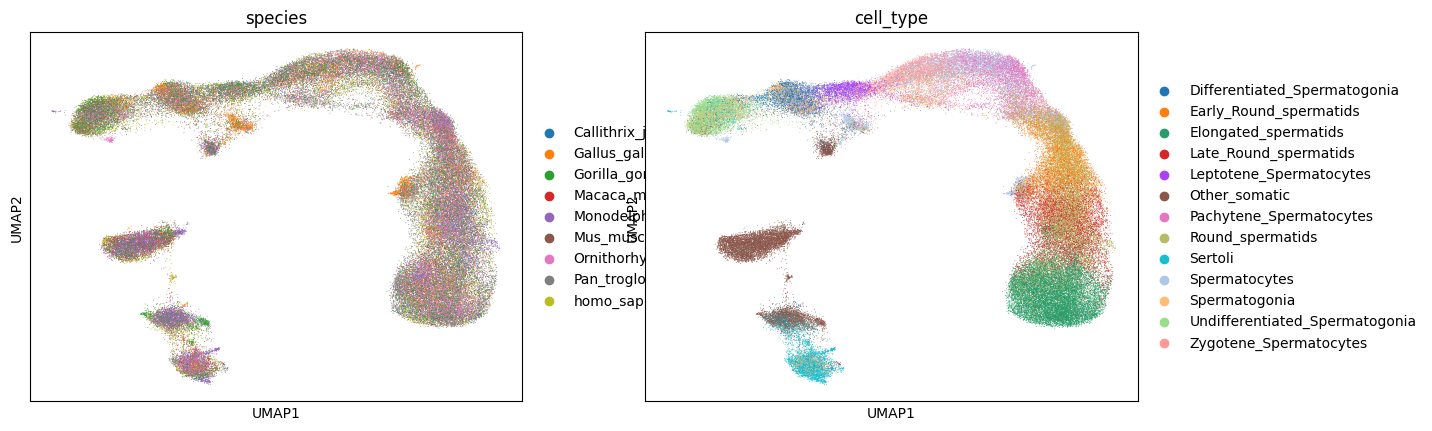

In [14]:
import importlib
import Henosis.evaluate
importlib.reload(Henosis.evaluate)
from Henosis.evaluate import evaluate_integration

integrated_adata = evaluate_integration(
    net,
    test_loader,
    species_to_adata=tokenized,
    #metadata_columns=["cluster"],
    # 如果不同物种列名不一样，改用：
     species_to_metadata_columns={
         "one":["cell_ontology_class","cell_type"],
         "homo_sapiens": ["cell_ontology_class","cell_type"],
         "Mus_musculus": ["cell_ontology_class","cell_type" ],
         "Macaca_mulatta": ["cell_ontology_class", "cell_type"],
         "Callithrix_jacchus": ["cell_ontology_class", "cell_type"],
         "Gallus_gallus": ["cell_ontology_class","cell_type" ],
         "Monodelphis_domestica": ["cell_ontology_class","cell_type" ],
         "Pan_troglodytes":["cell_ontology_class","cell_type"],
         "Gorilla_gorilla": ["cell_ontology_class","cell_type" ],
         "Ornithorhynchus_anatinus": ["cell_ontology_class", "cell_type"],
     },
    embedding="protein",
    use_mot_correction=True,
    correction_by="inferred_species",
    correction_kwargs={
        "max_rounds": 10,
        "n_clusters": 40,
        "assignment_mode": "sinkhorn",
    },
    umap_colors=["species", "cell_type"],
)

In [15]:
#integrated_adata.write('/mnt/public5/panguanyu/cross_species/code/sypy/umap_results/figure3/testis/hresa_testis_1_64_1.h5ad')